## Model Comparison

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

linear = pd.read_csv(
    "../results/linear_regression_results.csv",
    index_col=0
)

random_forest = pd.read_csv(
    "../results/random_forest_results.csv",
    index_col=0
)

### 1. Performance Metrics

In [45]:
model_metrics = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
    ],
    "MAE": [
        0.934,
        0.447,
    ],
    "RMSE": [
        1.318,
        0.733,
    ],
    "R2": [
        0.823,
        0.945,
    ],
})

model_metrics

,Model,MAE,RMSE,R2
0,Linear Regression,0.934,1.318,0.823
1,Random Forest,0.447,0.733,0.945


### 2. Calculate Fuel Consumption Categories

In [46]:
from data_setup import load_data, get_train_test_split

df = load_data()

X_train, X_test, y_train, y_test = get_train_test_split(df)

low_cutoff = y_train.quantile(0.33)
high_cutoff = y_train.quantile(0.67)

print("Low cutoff:", low_cutoff)
print("High cutoff:", high_cutoff)

Low cutoff: 11.200714285714286
High cutoff: 13.0675


In [47]:
def classify_consumption(value):
    if value < low_cutoff:
        return "Low"
    elif value < high_cutoff:
        return "Medium"
    else:
        return "High"

In [48]:
linear["actual_category"] = linear["actual"].apply(classify_consumption)
linear["predicted_category"] = linear["predicted"].apply(classify_consumption)

random_forest["actual_category"] = random_forest["actual"].apply(classify_consumption)
random_forest["predicted_category"] = random_forest["predicted"].apply(classify_consumption)

### 3. Calculate Category Accuracy

In [49]:
linear_category_accuracy = (
    linear["actual_category"] == linear["predicted_category"]
).mean()

rf_category_accuracy = (
    random_forest["actual_category"] == random_forest["predicted_category"]
).mean()

print("Linear Regression:", linear_category_accuracy)
print("Random Forest:", rf_category_accuracy)

Linear Regression: 0.8191823899371069
Random Forest: 0.8776443682104059


### 4. Graphical Comparisons


#### Prediction Error by Model

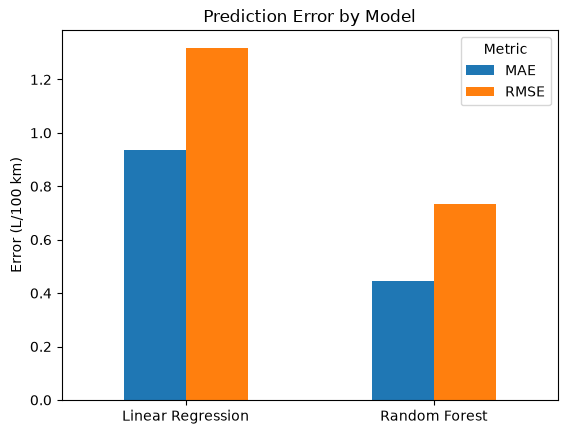

In [50]:
metrics_plot = model_metrics.set_index("Model")[["MAE", "RMSE"]]

metrics_plot.plot(kind="bar")

plt.ylabel("Error (L/100 km)")
plt.xlabel("")
plt.title("Prediction Error by Model")
plt.xticks(rotation=0)
plt.legend(title="Metric")

plt.show()

#### R² by Model

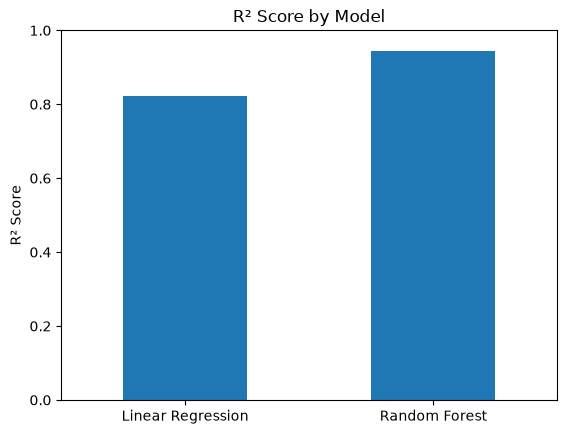

In [51]:
model_metrics.plot(
    x="Model",
    y="R2",
    kind="bar",
    legend=False,
)

plt.ylabel("R² Score")
plt.xlabel("")
plt.title("R² Score by Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.show()

#### Category Accuracy

In [52]:
category_accuracy = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
    ],
    "Category Accuracy": [
        linear_category_accuracy,
        rf_category_accuracy,
    ],
})

category_accuracy["Category Accuracy"] *= 100

Linear Regression: 81.9%
Random Forest: 87.8%


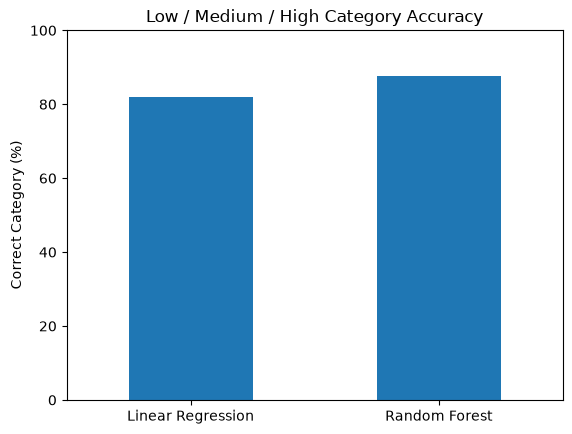

In [53]:
category_accuracy.plot(
    x="Model",
    y="Category Accuracy",
    kind="bar",
    legend=False,
)

print(f"Linear Regression: {linear_category_accuracy:.1%}")
print(f"Random Forest: {rf_category_accuracy:.1%}")

plt.ylabel("Correct Category (%)")
plt.xlabel("")
plt.title("Low / Medium / High Category Accuracy")
plt.ylim(0, 100)
plt.xticks(rotation=0)

plt.show()

### Individual Model Analysis


#### Linear Regression

In [54]:
linear_confusion = pd.crosstab(
    linear["actual_category"],
    linear["predicted_category"],
    rownames=["Actual"],
    colnames=["Predicted"]
)

linear_confusion

Predicted,High,Low,Medium
Actual,,,
High,2450,25,386
Low,6,2043,195
Medium,209,444,1238


#### Random Forest

In [55]:
rf_confusion = pd.crosstab(
    random_forest["actual_category"],
    random_forest["predicted_category"],
    rownames=["Actual"],
    colnames=["Predicted"]
)

rf_confusion

Predicted,High,Low,Medium
Actual,,,
High,2468,1,392
Low,1,2172,71
Medium,71,320,1500
